# PISA Example Using Public IceCube Data


Dataset must be obtained from the PRD 2023 paper of IceCube

https://dataverse.harvard.edu/dataset.xhtml?persistentId=doi:10.7910/DVN/B4RITM&version=1.0

## Setup

Usually you would need to export the location of the data, and the config files to `PISA_RESOURCES`. For this example however, the data is inside our package.

In [1]:
import numpy as np
from uncertainties import unumpy as unp
import matplotlib.pyplot as plt
import copy
import os
import pisa
from pisa.core.distribution_maker import DistributionMaker
from pisa.core.pipeline import Pipeline
from pisa.analysis.analysis import Analysis
from pisa import FTYPE, ureg

<< PISA is running in double precision (FP64) mode; numba is running on CPU (single core) >>


In [2]:
fridge_path = '/home/jp/icecube/wg-oscillations-fridge/analysis'

In [3]:
os.environ['PISA_RESOURCES'] = fridge_path

In [4]:
myfiles_path = '/home/jp/daemonflux/oscillations_release_2023'

In [5]:
## Model

We can now instantiate the `model` (given our configs) that we later fit to data. This now containes two `Pipelines` in a `DistributionMaker`, one for our neutrinos, and one for the background muons.

In [6]:
model = DistributionMaker([
    os.path.join(myfiles_path,"pisa_settings/pipeline/neutrino_pipeline.cfg"),
    os.path.join(myfiles_path,"pisa_settings/pipeline/muon_pipeline.cfg") # Nu pipeline is ok
])# "settings/pipeline/IceCube_3y_muons.cfg"])

[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")

[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/uncertainties/core.py:1024: UserWarning: Using UFloat objects with std_dev==0 may give unexpected results.
  warn("Using UFloat objects with std_dev==0 may give unexpected results.")



In [7]:
flux_stage = model.pipelines[0][2]

In [8]:
dir(flux_stage)

['__class__',
 '__delattr__',
 '__dict__',
 '__dir__',
 '__doc__',
 '__eq__',
 '__format__',
 '__ge__',
 '__getattribute__',
 '__gt__',
 '__hash__',
 '__init__',
 '__init_subclass__',
 '__le__',
 '__lt__',
 '__module__',
 '__ne__',
 '__new__',
 '__reduce__',
 '__reduce_ex__',
 '__repr__',
 '__setattr__',
 '__sizeof__',
 '__str__',
 '__subclasshook__',
 '__weakref__',
 '_apply_mode',
 '_attrs_to_hash',
 '_calc_mode',
 '_check_exp_keys_in_data',
 '_check_params',
 '_check_representation',
 '_data',
 '_debug_mode',
 '_error_method',
 '_eval_spline',
 '_param_selector',
 '_params',
 '_source_code_hash',
 'antipion_production',
 'apply',
 'apply_function',
 'apply_mode',
 'apply_times',
 'barr_param_names',
 'barr_param_signs',
 'calc_mode',
 'calc_times',
 'compute',
 'compute_function',
 'data',
 'debug_mode',
 'error_method',
 'expected_container_keys',
 'expected_params',
 'full_hash',
 'gradient_param_indices',
 'gradient_param_names',
 'gradient_params',
 'hash',
 'in_standalone_mode'

In [9]:
## Verifying that there are things loaded
#model.pipelines[0].data['numu_cc']['true_energy']
#model.pipelines[1].data['icc']['reco_energy']
#model.pipelines[2].data['total']['reco_energy']

In [10]:
# Confirming that the data has been loaded
loader = model.pipelines[0]
loader

stage number,name,calc_mode,apply_mode,has setup,has compute,has apply,# fixed params,# free params
0,csv_loader,events,events,True,False,True,0,0
1,honda_ip,"""flux_binning"": 200 (true_energy) x 100 (true_coszen)",events,True,True,False,1,0
2,mceq_barr_red,events,events,True,True,False,8,7
3,prob3,"""osc_binning"": 300 (true_energy) x 68 (true_coszen)",events,True,True,True,10,2
4,genie_sys,,events,True,False,True,0,2
5,dis_sys,,events,True,False,True,0,1
6,nutau_xsec,events,events,True,True,True,1,0
7,aeff,,events,False,False,True,3,2
8,hist,events,"""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)",True,False,True,0,0
9,csv_hypersurfaces,"""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)","""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)",True,True,True,0,6


Our model has a number of free parameters, that will be used in our fit to the data

In [11]:
model.params.free

name,value,nominal_value,range,prior,units,is_fixed
delta_index,0,0,"[-0.5, 0.5]",+/- 0.1,dimensionless,False
barr_af_Pi,0,0,"[-3.15, 3.15]",+/- 0.63,dimensionless,False
barr_g_Pi,0,0,"[-1.5, 1.5]",+/- 0.3,dimensionless,False
barr_h_Pi,0,0,"[-0.75, 0.75]",+/- 0.15,dimensionless,False
barr_w_K,0,0,"[-2.0, 2.0]",+/- 0.4,dimensionless,False
barr_y_K,0,0,"[-1.5, 1.5]",+/- 0.3,dimensionless,False
barr_w_antiK,0,0,"[-2.0, 2.0]",+/- 0.4,dimensionless,False
theta23,49.7,49.7,"[0, 90]",uniform,degree,False
deltam31,0.002525,0.002525,"[0.001, 0.007]",uniform,electron_volt ** 2,False
Genie_Ma_QE,0,0,"[-2.0, 2.0]",+/- 1.0,dimensionless,False


The two pipelines are quite different, with most complexity in the neutrino pipeline, that has several `Stage`s and free parameters:

In [12]:
model.pipelines[0].stages[2].params

name,value,nominal_value,range,prior,units,is_fixed
energy_pivot,24.0901,24.0901,,,gigaelectron_volt,True
delta_index,0,0,"[-0.5, 0.5]",+/- 0.1,dimensionless,False
pion_ratio,0,0,"[-0.25, 0.25]",+/- 0.05,dimensionless,True
barr_af_Pi,0,0,"[-3.15, 3.15]",+/- 0.63,dimensionless,False
barr_g_Pi,0,0,"[-1.5, 1.5]",+/- 0.3,dimensionless,False
barr_h_Pi,0,0,"[-0.75, 0.75]",+/- 0.15,dimensionless,False
barr_i_Pi,0,0,"[-0.61, 0.61]",+/- 0.122,dimensionless,True
barr_w_K,0,0,"[-2.0, 2.0]",+/- 0.4,dimensionless,False
barr_x_K,0,0,"[-0.5, 0.5]",+/- 0.1,dimensionless,True
barr_y_K,0,0,"[-1.5, 1.5]",+/- 0.3,dimensionless,False


While the muon pipleine is rather simple

In [13]:
csv = model.pipelines[0].stages[9]

## Retrieve Outputs

We can get individual outputs from just a pipleine like so. This fetches outputs from the neutrino pipleine, which are 12 maps.

In [35]:
maps = model.pipelines[0].get_outputs()

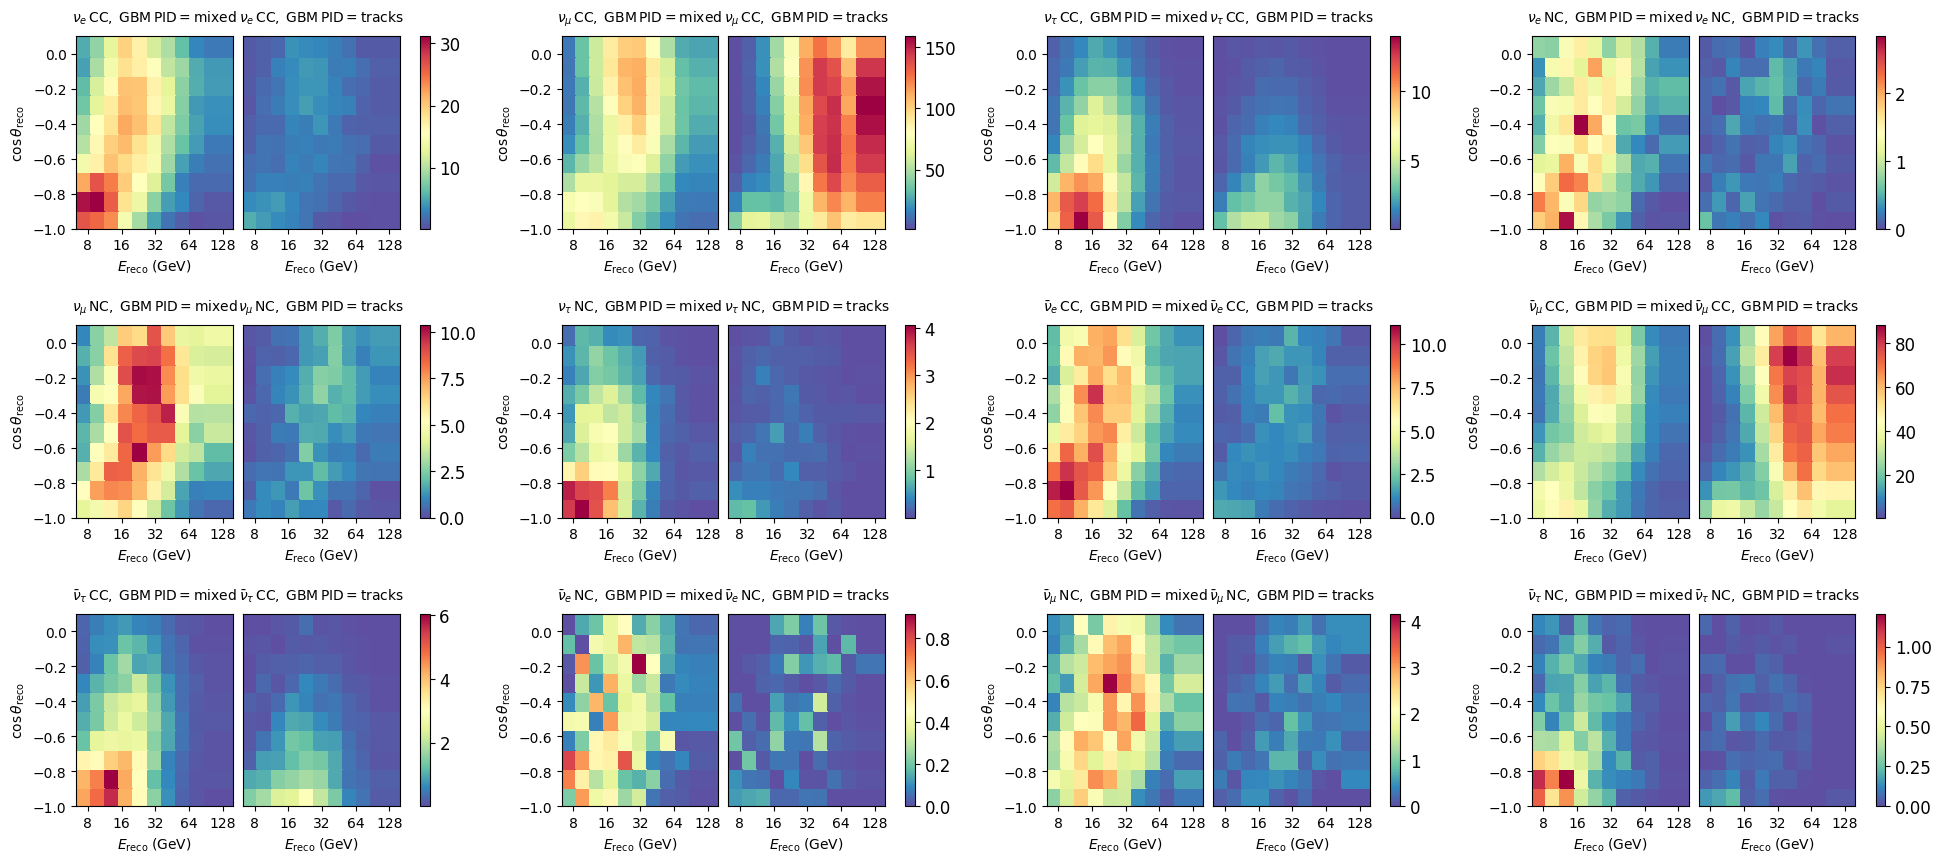

In [16]:
fig, axes = plt.subplots(3,4, figsize=(24,10))
plt.subplots_adjust(hspace=0.5)
axes = axes.flatten()

for m, ax in zip(maps, axes):
    m.plot(ax=ax, full_ax=ax)

If we are interested in just the total expecatation from the full model (all neutrinos + muons), we can do the following:

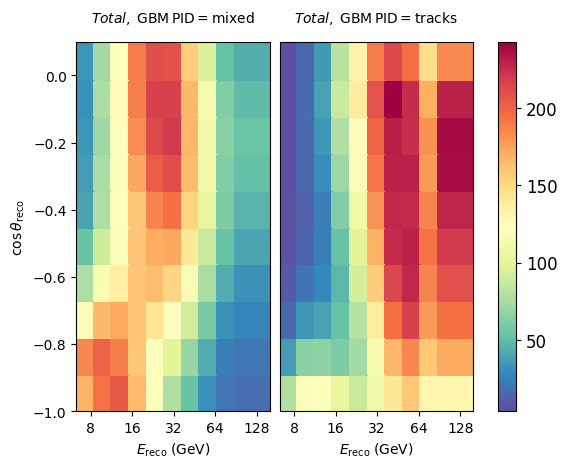

In [17]:
model.get_outputs(return_sum=True).plot()

## Diff plots

Let's explore how a change in one of our nuisance parameters affects the expected counts per bin. Here we choose a *hole ice* parameter and move it a smidge.

In [18]:
# reset all free parameters to put them back to nominal values
model.reset_free()
nominal = model.get_outputs(return_sum=True)

# shift one parameter
model.params.hole_ice_p0.value = 1.
model.params.hole_ice_p0.value = 1.

#model.params['delta_index'].value=-0.04
#model.params['deltam31'].value=0.0023 ## This did not work yet

sys = model.get_outputs(return_sum=True)

(<Figure size 640x480 with 3 Axes>,
 <Axes: title={'center': '$Total,{\\;}{\\rm GBM\\,PID}={\\rm mixed}$'}, xlabel='$E_{\\rm reco} \\; \\left( \\mathrm{GeV} \\right)$', ylabel='$\\cos{\\theta}_{\\rm reco}$'>,
 None)

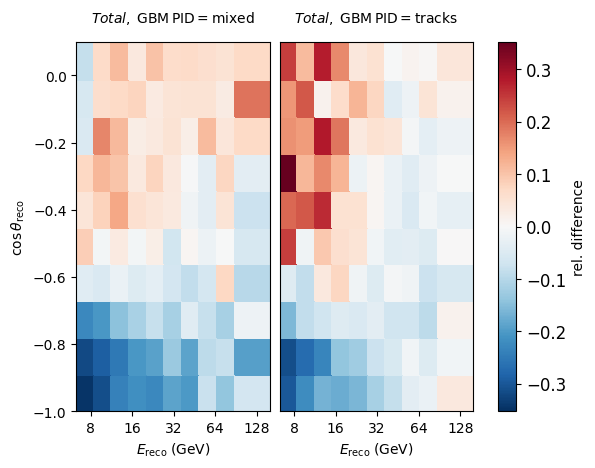

In [19]:
((nominal[0] - sys[0])/nominal[0]).plot(symm=True, clabel="rel. difference")

## Get Data

We can load the real observed data too. This is a Pipeline with no free parameters, as the data is of course fixed.
NB: When developping a new analysis you will **not** be allowed to look at the data as we do here before the box opening (c.f. *blindness*).

In [20]:
# real data
data_maker = Pipeline(os.path.join(myfiles_path,"pisa_settings/pipeline/data_pipeline.cfg"))
data = data_maker.get_outputs()

In [21]:
data_maker

stage number,name,calc_mode,apply_mode,has setup,has compute,has apply,# fixed params,# free params
0,csv_data_hist,events,"""reco_binning"": 10 (reco_energy) x 10 (reco_coszen) x 2 (pid)",True,False,False,0,0


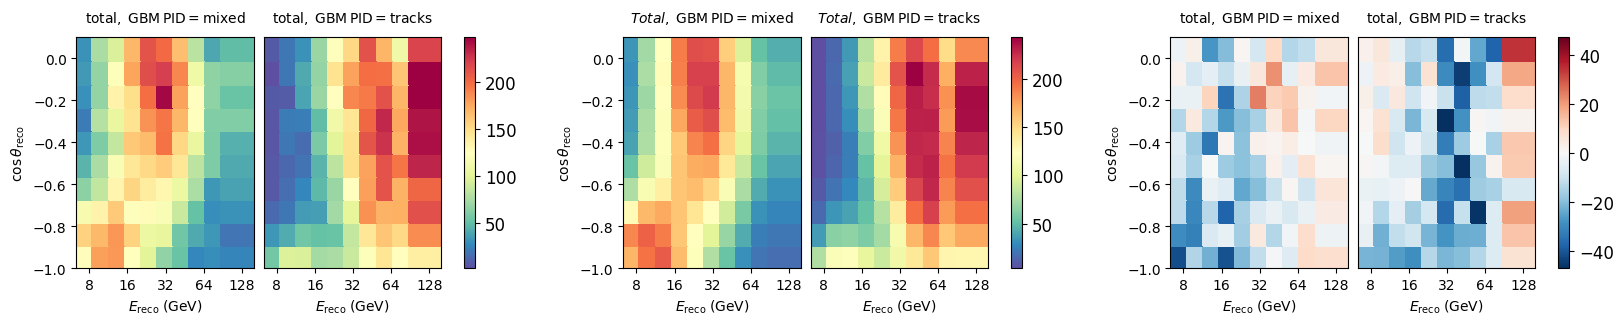

In [22]:
fig, ax = plt.subplots(1, 3, figsize=(20, 3))

model.reset_free()
nominal = model.get_outputs(return_sum=True)

data.plot(ax=ax[0], title="Data", full_ax=ax[0])
nominal.plot(ax=ax[1], title="Model", full_ax=ax[1])
(data - nominal).plot(ax=ax[2], symm=True, title="Diff", full_ax=ax[2])

## Fitting

For fitting we need to configure a minimizer, several standard cfgs are available, but you can also define your own.
For the fit we need to choose a `metric`, and by default, theta23 octants, which are quasi degenerate, are fit seperately, which means two fits are run.

In [23]:
local_fit_minuit = {
    "method": "iminuit",
    "method_kwargs": {
        "errors": 0.1,
        "precision": 1e-14,  # default: double precision
        "tol": 1e-2,  # default: 0.1
        "run_simplex": False,
        "run_migrad": True
    },
    "local_fit_kwargs": None
}

In [24]:
fit_octant = {
    "method": "octants",
    "method_kwargs": {
        "angle": "theta23",
        "inflection_point": 45 * ureg.degrees,
    },
    "local_fit_kwargs": local_fit_minuit
}

In [25]:
ana = Analysis()
ana.pprint=False

In [26]:
result = ana.fit_recursively(
    data_dist=data,
    hypo_maker=model,
    metric='chi2',
    external_priors_penalty=None,
    **fit_octant,
)

Here we can view the bestfit parameters - the result of our fit.
We have run two fits (separately for each theta23 octant), and the best result is stored in `results[0]` (both fits are also available under `results[1]`)

In [27]:
result.metric_val

202.39847894612657

In [28]:
result.params.free

name,value,nominal_value,range,prior,units,is_fixed
delta_index,0.0654395,0,"[-0.5, 0.5]",+/- 0.1,dimensionless,False
barr_af_Pi,0.238996,0,"[-3.15, 3.15]",+/- 0.63,dimensionless,False
barr_g_Pi,-0.0562287,0,"[-1.5, 1.5]",+/- 0.3,dimensionless,False
barr_h_Pi,-0.0182287,0,"[-0.75, 0.75]",+/- 0.15,dimensionless,False
barr_w_K,0.083749,0,"[-2.0, 2.0]",+/- 0.4,dimensionless,False
barr_y_K,0.107984,0,"[-1.5, 1.5]",+/- 0.3,dimensionless,False
barr_w_antiK,-0.0091514,0,"[-2.0, 2.0]",+/- 0.4,dimensionless,False
theta23,45.3908,49.7,"[0, 90]",uniform,degree,False
deltam31,0.00249346,0.002525,"[0.001, 0.007]",uniform,electron_volt ** 2,False
Genie_Ma_QE,0.0326216,0,"[-2.0, 2.0]",+/- 1.0,dimensionless,False


In [49]:
print(np.sin(np.deg2rad(result['params']['theta23'].value))**2, "||| 0.51+/-0.05")
print((result['params']['deltam31'].value-result['params']['deltam21'].value)*1E3, "||| 2.41+/-0.07")

0.5068207860972875 dimensionless ||| 0.51+/-0.05
2.4195605067574664 electron_volt ** 2 ||| 2.41+/-0.07


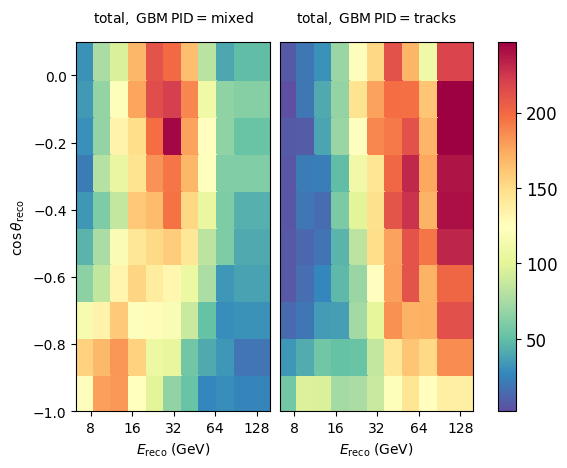

In [29]:
data.plot()

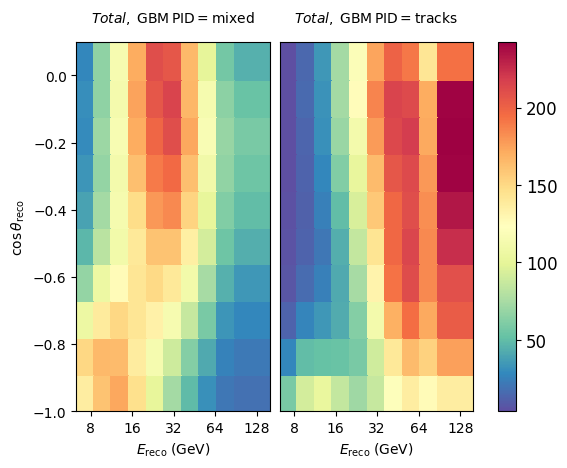

In [30]:
template = model.get_outputs(return_sum=True)
template.plot()

Let's see how good that fit looks like. We here construct signed mod_chi2 maps by hand.
You can see that after the fit, it improved considerably, and the distribution of chi2 values is now more uniform - not much features can be seen anymore.

[ WARNING] /home/jp/software/pisa/pisa/core/map.py:1909: FutureWarning: AffineScalarFunc.__abs__() is deprecated. It will be removed in a future release.
  'hist': np.abs(self.hist)

[ WARNING] /home/jp/software/pisa/pisa/core/map.py:1909: FutureWarning: AffineScalarFunc.__abs__() is deprecated. It will be removed in a future release.
  'hist': np.abs(self.hist)



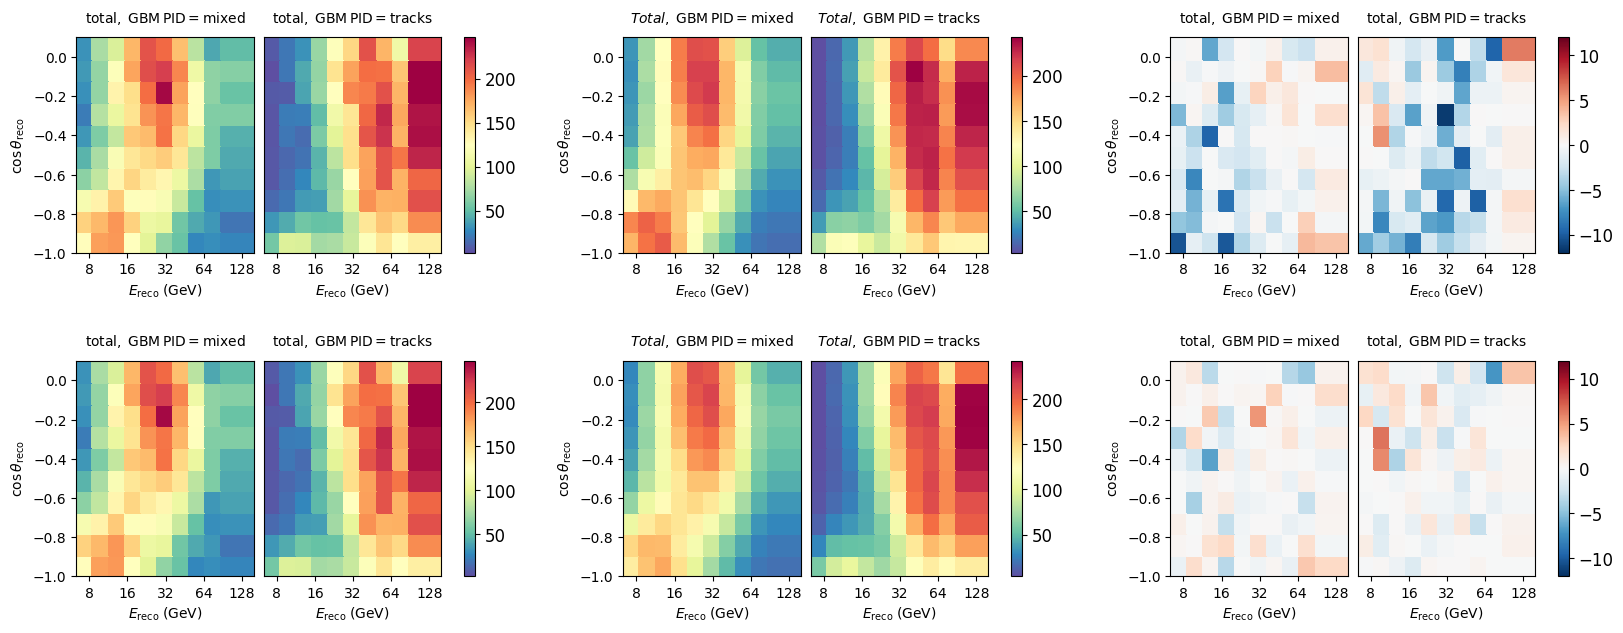

In [31]:
fig, ax = plt.subplots(2, 3, figsize=(20, 7))
plt.subplots_adjust(hspace=0.5)

bestfit = model.get_outputs(return_sum=True)

data.plot(ax=ax[0,0],title="Data", full_ax=ax[0,0])
nominal.plot(ax=ax[0,1], full_ax=ax[0,1], title="Nominal")
diff = data - nominal
(abs(diff)*diff/(nominal + unp.std_devs(nominal.hist['total']))).plot(ax=ax[0,2], full_ax=ax[0,2],
                                                                      symm=True, title=r"signed $\chi^2$", vmin=-12, vmax=12)

data.plot(ax=ax[1,0], full_ax=ax[1,0], title="Data")
bestfit.plot(ax=ax[1,1], full_ax=ax[1,1], title="Bestfit")
diff = data - bestfit
(abs(diff)*diff/(bestfit + unp.std_devs(bestfit.hist['total']))).plot(ax=ax[1,2], full_ax=ax[1,2], 
                                                                      symm=True, title=r"signed $\chi^2$", vmin=-12, vmax=12)

When checking the chi2 value from the fitted model, you maybe see that it is around 113, while in the minimizer loop we saw it converged to 116. It is important to keep in mind that in the fit we had extended the metric with prior penalty terms. When we add those back we get the identical number as reported in the fit.

In [32]:
print(data.metric_total(nominal, 'mod_chi2'))
print(data.metric_total(bestfit, 'mod_chi2'))

444.4494034075278
198.84500316846496


Evaluating other metrics just for fun:

In [33]:
for metric in pisa.utils.stats.ALL_METRICS:
    try:
        print('%s = %.3f'%(metric,data.metric_total(bestfit, metric)))
    except:
        print('%s failed'%metric)

llh = -100.268
conv_llh = -99.501
barlow_llh = -1844.360
mcllh_mean = -724.301
mcllh_eff = -724.278
generalized_poisson_llh failed
chi2 = 200.442
mod_chi2 = 198.845
[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/numpy/core/_methods.py:114: FutureWarning: AffineScalarFunc.__ge__() is deprecated. It will be removed in a future release.
  return ufunc(*args, out=out, **kwargs)

[ WARNING] /home/jp/anaconda3/envs/pisa/lib/python3.10/site-packages/numpy/core/_methods.py:114: FutureWarning: AffineScalarFunc.__le__() is deprecated. It will be removed in a future release.
  return ufunc(*args, out=out, **kwargs)

correct_chi2 = 1081.097
weighted_chi2 failed


Adding prior penalty terms

## Storing the results to a file

Since the fit took a while, it might be useful to store the results to a file. (NB: in this example we use a temp file, but in real life you would of course just use a real pathname instead!)

In [34]:
outdir = '/home/jp/daemonflux/oscillations_release_2023/pisa_results/'
filename = 'published.json'
pisa.utils.fileio.to_file(result, outdir+filename)

[ WARNING] Directory "/home/jp/daemonflux/oscillations_release_2023/pisa_results" already exists


To reload, we can read the file. But to get PISA objects back, they need to instantiated

In [26]:
result_reload = pisa.utils.fileio.from_file(temp.name)
bestfit_params = pisa.core.ParamSet(result_reload[0]['params']).free
bestfit_params
temp.close()

## Profiling

To understand what parts of the model were executed how many times, and how long it took, the profiling  can help:

In [27]:
model.pipelines[0].report_profile()

data csv_loader
- setup:  Total time 0.00000 s, n calls: 0, time/call: 0.00000 s
- calc:   Total time 0.00000 s, n calls: 0, time/call: 0.00000 s
- apply:  Total time 1.34596 s, n calls: 817, time/call: 0.00165 s
flux honda_ip
- setup:  Total time 0.00000 s, n calls: 0, time/call: 0.00000 s
- calc:   Total time 25.08353 s, n calls: 1, time/call: 25.08353 s
- apply:  Total time 0.00072 s, n calls: 817, time/call: 0.00000 s
flux barr_simple
- setup:  Total time 0.00000 s, n calls: 0, time/call: 0.00000 s
- calc:   Total time 118.13966 s, n calls: 330, time/call: 0.35800 s
- apply:  Total time 0.00091 s, n calls: 817, time/call: 0.00000 s
osc prob3
- setup:  Total time 0.00000 s, n calls: 0, time/call: 0.00000 s
- calc:   Total time 339.71126 s, n calls: 290, time/call: 1.17142 s
- apply:  Total time 73.15262 s, n calls: 817, time/call: 0.08954 s
aeff aeff
- setup:  Total time 0.00000 s, n calls: 0, time/call: 0.00000 s
- calc:   Total time 0.00056 s, n calls: 290, time/call: 0.00000 s
- 